# **Arousal Regression on WESAD — Regression Pipeline**

This notebook implements the regression stage of the WESAD pipeline: predicting continuous
**arousal** from the physiological features, as a secondary extension to the classification.
It is independent of the classification notebook and can be run on its own.

## Methodology
The target is the self-reported **SAM arousal** score (scale 1-9), collected once per
(subject, condition). All windows of the same segment therefore share the same target: the
regression is intentionally **coarse-grained**. Because windows sharing a target must never
be split across folds, **Leave-One-Subject-Out (LOSO)** validation is used — subject-wise
splitting keeps all windows of a subject together and avoids leakage. Every learned step
(imputation, scaling, feature selection, tuning) is fitted inside the training folds.

Given the coarse target, models are evaluated at **two resolutions**: at the
**window** level (all windows) and, more honestly, at the **(subject, condition)** level, by
averaging the per-window predictions of each segment and comparing them against the single
true value. The condition-level metrics reflect the true resolution of the target (3 values
per subject) rather than the inflated window count.

## Structure
**1. Target preparation** — parse the SAM arousal score from each `SX_quest.csv` and align
it to the feature windows via (subject, condition).

**2. Regression under LOSO** — three regressors (Decision Tree, k-NN, Random
Forest) plus a mean-predictor baseline, tuned inside folds. Metrics: RMSE, MAE, R².

**3. Two-resolution evaluation** — window-level and condition-level metrics.

**4. Analysis** — predicted-vs-true plots and model comparison.

## Dependencies
`feature_selectors.py` (shared leakage-safe transformers) must sit next to this notebook.
External libraries: scikit-learn, scipy (statistical tests), matplotlib, pandas, numpy.
The `SX_quest.csv` files from the original WESAD dataset are required for the target.

## **0. Imports**

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functools import partial

from sklearn.model_selection import LeaveOneGroupOut, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from collections import Counter

# Shared imports for feature selection
from feature_selectors import MissingnessFilter, CorrelationFilter

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

# Seeded mutual-information scorer for regression
mi_reg = partial(mutual_info_regression, random_state=RANDOM_STATE)

## **1. Setup of regression pipeline**

In [3]:
# Paths to the feature CSVs
FEATURES_CSV = os.path.join('Preprocessing_and_Feature_Selection', 'Chest','chest_outputs', 'features.csv')
QUEST_DIR = 'WESAD_quest'          # folder with SAM CSVs

META = ['label', 'label_name', 'subject_id']
# missingness cutoff, matches feature selection
NA_THRESHOLD = 0.30
                            
# Mapping from condition names to integer labels
COND_NAME_TO_LABEL = {'Base': 1, 'TSST': 2, 'Fun': 3}

### 1.1 Target preparation

Each `SX_quest.csv` stores, on its `# DIM` lines, the SAM valence and arousal for every
condition, in the order given by the `# ORDER` line (which varies per subject). The parser
reads that order, then the DIM rows, and keeps arousal (second value) for the three
conditions used here (baseline, stress, amusement).

In [4]:

QUEST_CONDITIONS = {'Base', 'TSST', 'Fun', 'Medi 1', 'Medi 2'}


def parse_sam(path):
    """Return {label_id: arousal} for one subject's quest.csv (baseline/stress/amusement)."""
    with open(path, 'r') as f:
        lines = f.read().splitlines()
    order, dim_rows = None, []
    for ln in lines:
        parts = [p.strip() for p in ln.replace('\r', '').split(';')]
        tag = parts[0]
        if tag == '# ORDER':
            order = [p for p in parts[1:] if p]
        elif tag == '# DIM':
            dim_rows.append([p for p in parts[1:] if p != ''])

    # DIM rows align positionally with the questionnaire conditions in ORDER
    assert order is not None, f'no # ORDER line in {path}'
    order_q = [c for c in order if c in QUEST_CONDITIONS]
    assert len(order_q) == len(dim_rows), (
        f'{path}: {len(order_q)} conditions with a questionnaire '
        f'but {len(dim_rows)} DIM rows')

    out = {}
    for cond_name, row in zip(order_q, dim_rows):
        if cond_name in COND_NAME_TO_LABEL and len(row) >= 2:
            valence, arousal = int(row[0]), int(row[1])
            out[COND_NAME_TO_LABEL[cond_name]] = arousal
    return out

In [5]:
def load_features(path):
    """"Load the features CSV and return a DataFrame with subject_id and label as integers."""
    df = pd.read_csv(path)
    df = df.dropna(subset=['subject_id', 'label']).reset_index(drop=True)
    df['subject_id'] = df['subject_id'].astype(int)
    df['label'] = df['label'].astype(int)
    return df

features = load_features(FEATURES_CSV)
features = features[features['label'].isin(COND_NAME_TO_LABEL.values())].reset_index(drop=True)

# Build the (subject, condition) -> arousal table from the quest files
arousal_map = {}   
for sid in sorted(features['subject_id'].unique()):
    quest_path = os.path.join(QUEST_DIR, f'S{sid}_quest.csv')
    sam = parse_sam(quest_path)
    for label_id, arousal in sam.items():
        arousal_map[(sid, label_id)] = arousal

# Attach the target to every window via its (subject, condition)
features['arousal'] = features.apply(
    lambda r: arousal_map.get((r['subject_id'], r['label']), np.nan), axis=1)
features = features.dropna(subset=['arousal']).reset_index(drop=True)
features['arousal'] = features['arousal'].astype(float)

print(f'{len(features)} windows with a valid arousal target')
print(f'arousal range: {features["arousal"].min():.0f} - {features["arousal"].max():.0f}')

6123 windows with a valid arousal target
arousal range: 1 - 9


           mean   std  min  max
baseline   2.53  0.88  2.0  5.0
stress     6.85  1.75  3.0  9.0
amusement  3.01  1.55  1.0  7.0


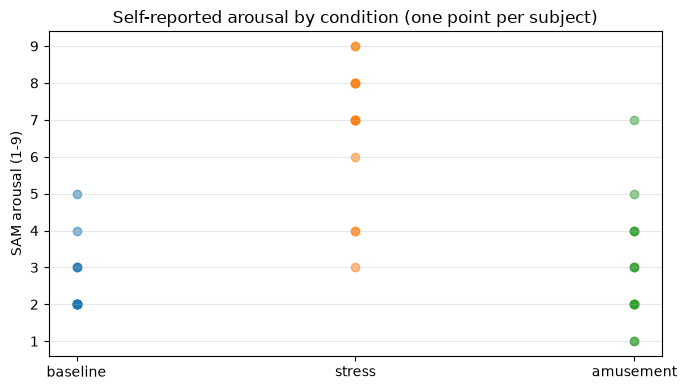

In [37]:
# Visual analysis of arousal by condition
cond_names = {1: 'baseline', 2: 'stress', 3: 'amusement'}
summary = (features.groupby('label')['arousal']
           .agg(['mean', 'std', 'min', 'max']).round(2))
summary.index = [cond_names[i] for i in summary.index]
print(summary)

fig, ax = plt.subplots(figsize=(7, 4))
for lab in sorted(cond_names):
    vals = features.loc[features['label'] == lab].groupby('subject_id')['arousal'].first()
    ax.scatter([cond_names[lab]] * len(vals), vals, alpha=0.5)
ax.set_ylabel('SAM arousal (1-9)')
ax.set_title('Self-reported arousal by condition (one point per subject)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.2 Building the regression matrices

In [38]:
# Prepare the data for regression
feature_cols = [c for c in features.columns if c not in META + ['arousal']]

X = features[feature_cols].values
y = features['arousal'].values
groups = features['subject_id'].values
conditions = features['label'].values         

print(f'{X.shape[0]} windows, {len(feature_cols)} features, {features["subject_id"].nunique()} subjects')

6123 windows, 80 features, 15 subjects


### 1.3 Define Regression pipeline

The same chain as in classification, adapted to regression: missingness filtering, median
imputation, standardisation, correlation filter, and univariate selection by
`mutual_info_regression`. Fitted inside each fold so the held-out subject never influences
any learned step.

In [41]:
def make_pipeline(reg):
    return Pipeline([
        ('missingness', MissingnessFilter(threshold=NA_THRESHOLD)),
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('redundancy', CorrelationFilter(threshold=0.9,
                                         score_func=mutual_info_regression,
                                         random_state=RANDOM_STATE)),
        ('select', SelectKBest(mi_reg, k=15)),
        ('reg', reg),
    ])

# Applied regressors, plus a mean-predictor baseline for context
models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'k-NN':          KNeighborsRegressor(),
    'Random Forest': RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
}

### 1.4 Hyperparameter search space

The number of selected features `k` is tuned jointly with each regressor's parameters. Grids are kept small to keep the nested search affordable.

In [42]:
K_GRID = [10, 15, 20]

param_grids = {
    'Mean baseline': {},
    'Decision Tree': {
        'select__k': K_GRID,
        'reg__max_depth': [None, 3, 5, 10],
        'reg__min_samples_leaf': [1, 5],
    },
    'k-NN': {
        'select__k': K_GRID,
        'reg__n_neighbors': [5, 11, 21],
        'reg__weights': ['uniform', 'distance'],
    },
    'Random Forest': {
        'select__k': K_GRID,
        'reg__n_estimators': [200, 400],
        'reg__max_depth': [None, 10],
    },
}

## **2. LOSO evaluation**

For each model, an outer LOSO loop evaluates while an inner LOSO grid search tunes on the
training subjects only. Out-of-fold predictions are collected for every window; from these,
metrics are computed both at the **window** level and at the **(subject, condition)** level, the latter by averaging per-segment predictions against the single true value.
RMSE, MAE and R² are reported; per-subject R² vectors feed the statistical comparison.

In [ ]:
# Nested LOSO regression with hyperparameter tuning
outer_cv = LeaveOneGroupOut()
inner_cv = LeaveOneGroupOut()

def nested_loso_regression(reg, param_grid, X, y, groups):
    """Return out-of-fold predictions plus per-subject R2 and MAE, keyed by subject id."""
    y_pred = np.full(len(y), np.nan)
    subject_r2, subject_mae = {}, {}
    for train_idx, test_idx in outer_cv.split(X, y, groups):
        sid = int(groups[test_idx][0])
        # MAE tuning
        if param_grid:
            search = GridSearchCV(make_pipeline(reg), param_grid,
                                  scoring='neg_mean_absolute_error', cv=inner_cv, n_jobs=-1)
            search.fit(X[train_idx], y[train_idx], groups=groups[train_idx])
            est = search
        else:
            est = make_pipeline(reg).fit(X[train_idx], y[train_idx])
        pred = est.predict(X[test_idx])
        y_pred[test_idx] = pred

        # Per-subject scores are keyed by subject id: a paired test
        # must compare the same subject across models, and positional alignment breaks
        # silently if a subject is ever skipped for one model and not another
        subject_mae[sid] = mean_absolute_error(y[test_idx], pred)

        # R2 undefined when the subject has constant arousal
        if np.ptp(y[test_idx]) > 0:     
            subject_r2[sid] = r2_score(y[test_idx], pred)
    return y_pred, subject_r2, subject_mae

def condition_level(y_true, y_pred, groups, conditions):
    """Aggregate window predictions to one value per (subject, condition), return the
    aggregated true and predicted arrays."""
    df = pd.DataFrame({'subject': groups, 'condition': conditions,
                       'y_true': y_true, 'y_pred': y_pred})
    agg = df.groupby(['subject', 'condition']).agg(
        y_true=('y_true', 'first'), y_pred=('y_pred', 'mean')).reset_index()
    return agg['y_true'].values, agg['y_pred'].values

In [44]:
# Run the regressions and collect metrics
results = {}
for name, reg in models.items():
    print(f'Evaluating {name} ...')
    y_pred, subj_r2, subj_mae = nested_loso_regression(reg, param_grids[name], X, y, groups)
    # window-level metrics
    rmse_w = np.sqrt(mean_squared_error(y, y_pred))
    mae_w = mean_absolute_error(y, y_pred)
    r2_w = r2_score(y, y_pred)
    # condition-level metrics
    yt_c, yp_c = condition_level(y, y_pred, groups, conditions)
    rmse_c = np.sqrt(mean_squared_error(yt_c, yp_c))
    mae_c = mean_absolute_error(yt_c, yp_c)
    r2_c = r2_score(yt_c, yp_c)
    results[name] = dict(y_pred=y_pred, subject_r2=subj_r2, subject_mae=subj_mae,
                         rmse_w=rmse_w, mae_w=mae_w, r2_w=r2_w,
                         rmse_c=rmse_c, mae_c=mae_c, r2_c=r2_c,
                         yt_c=yt_c, yp_c=yp_c)
    print(f'  window level:    RMSE {rmse_w:.3f}  MAE {mae_w:.3f}  R2 {r2_w:.3f}')
    print(f'  condition level: RMSE {rmse_c:.3f}  MAE {mae_c:.3f}  R2 {r2_c:.3f}')

# Report which subjects, if any, were excluded from the per-subject R2 vectors
all_subj = set(int(s) for s in np.unique(groups))
r2_subj = set(results['k-NN']['subject_r2'])
if all_subj - r2_subj:
    print(f'\nsubjects excluded from per-subject R2 (constant arousal): {sorted(all_subj - r2_subj)}')
else:
    print(f'\nall {len(all_subj)} subjects have a defined per-subject R2')

Evaluating Mean baseline ...
  window level:    RMSE 2.359  MAE 2.007  R2 -0.022
  condition level: RMSE 2.434  MAE 2.044  R2 -0.031
Evaluating Decision Tree ...
  window level:    RMSE 2.270  MAE 1.779  R2 0.054
  condition level: RMSE 2.309  MAE 1.819  R2 0.071
Evaluating k-NN ...
  window level:    RMSE 1.867  MAE 1.427  R2 0.360
  condition level: RMSE 1.848  MAE 1.466  R2 0.405
Evaluating Random Forest ...
  window level:    RMSE 2.099  MAE 1.671  R2 0.191
  condition level: RMSE 2.267  MAE 1.850  R2 0.105

all 15 subjects have a defined per-subject R2


### 2.1 Summary table

In [45]:
# Summarize the results in a DataFrame
reg_summary = pd.DataFrame({
    'RMSE (window)':    {m: results[m]['rmse_w'] for m in models},
    'MAE (window)':     {m: results[m]['mae_w']  for m in models},
    'R2 (window)':      {m: results[m]['r2_w']   for m in models},
    'RMSE (condition)': {m: results[m]['rmse_c'] for m in models},
    'MAE (condition)':  {m: results[m]['mae_c']  for m in models},
    'R2 (condition)':   {m: results[m]['r2_c']   for m in models},
}).round(3)
reg_summary

,RMSE (window),MAE (window),R2 (window),RMSE (condition),MAE (condition),R2 (condition)
Mean baseline,2.359,2.007,-0.022,2.434,2.044,-0.031
Decision Tree,2.270,1.779,0.054,2.309,1.819,0.071
k-NN,1.867,1.427,0.360,1.848,1.466,0.405
Random Forest,2.099,1.671,0.191,2.267,1.850,0.105


## **3. Results analysis**
### 3.1 Visual analysis of predicted vs. true arousal

Each point is one (subject, condition): the averaged prediction against the single true
arousal. Points near the diagonal indicate accurate prediction. The mean baseline collapses
onto a horizontal line, giving a visual reference for what a non-informative model looks like.

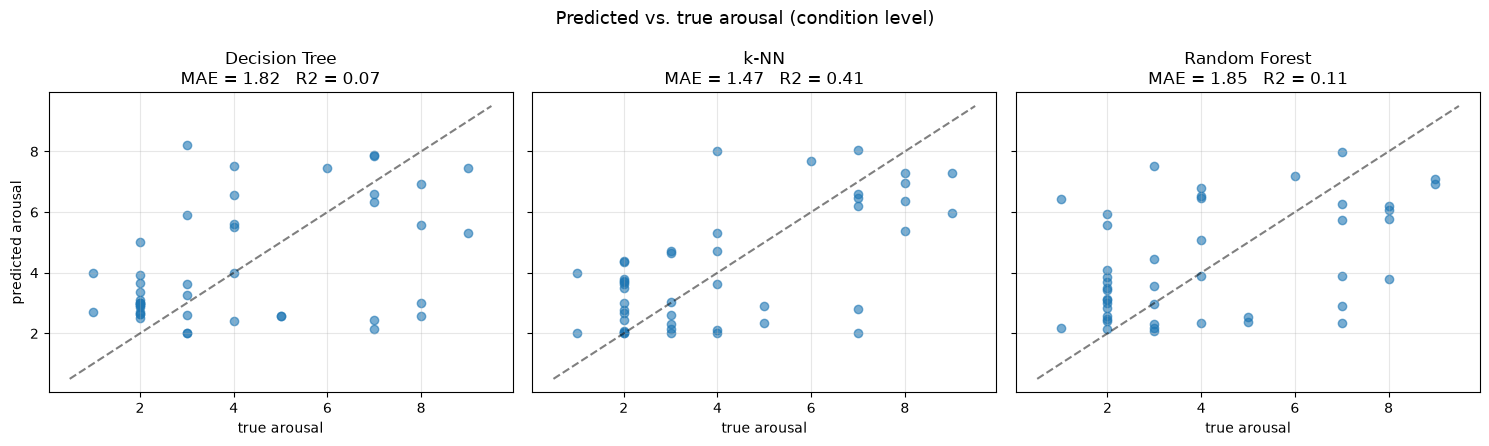

In [46]:
# Visualize the condition-level predictions
reg_models = [m for m in models if m != 'Mean baseline']
fig, axes = plt.subplots(1, len(reg_models), figsize=(5 * len(reg_models), 4.5), sharey=True)
for ax, name in zip(axes, reg_models):
    yt, yp = results[name]['yt_c'], results[name]['yp_c']
    ax.scatter(yt, yp, alpha=0.6)
    lims = [min(yt.min(), yp.min()) - 0.5, max(yt.max(), yp.max()) + 0.5]
    ax.plot(lims, lims, 'k--', alpha=0.5)
    ax.set_xlabel('true arousal')
    ax.set_title(f'{name}\nMAE = {results[name]["mae_c"]:.2f}   R2 = {results[name]["r2_c"]:.2f}')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('predicted arousal')
fig.suptitle('Predicted vs. true arousal (condition level)', fontsize=13)
plt.tight_layout()
plt.show()

### 3.2 Statistical comparison
Two comparisons are performed. First, each regressor is tested against the mean baseline using paired Wilcoxon tests on per-subject R²
 and MAE, with Holm correction. Second, differences among regressors are assessed with a Friedman test, followed by corrected pairwise Wilcoxon tests when needed. Mean differences are also reported, since with only 15 subjects a non-significant result does not prove that the models are equivalent.

In [47]:
def holm_correction(pvals):
    """Return Holm adjusted p-values for a list of raw p-values."""
    m = len(pvals)
    order = np.argsort(pvals)
    adjusted = np.empty(m)
    running_max = 0.0
    for rank, idx in enumerate(order):
        val = (m - rank) * pvals[idx]
        running_max = max(running_max, val)
        adjusted[idx] = min(running_max, 1.0)
    return adjusted

reg_names = [m for m in models if m != 'Mean baseline']

# Subject-level comparison across models
common = sorted(set.intersection(*[set(results[m]['subject_r2']) for m in models]))
print(f'{len(common)} subjects with a defined per-subject R2 in every model')

def vec(model, metric='subject_r2'):
    return np.array([results[model][metric][s] for s in common])

# 1. Do the regressors beat the trivial baseline mean predictor?
for metric, better in [('subject_r2', 'higher'), ('subject_mae', 'lower')]:
    raw_p, rows = [], []
    base = vec('Mean baseline', metric)
    for name in reg_names:
        m_scores = vec(name, metric)
        _, p = wilcoxon(base, m_scores, zero_method='pratt')
        raw_p.append(p)
        rows.append({'model': name,
                     'baseline': round(base.mean(), 3),
                     'model score': round(m_scores.mean(), 3),
                     'delta': round(m_scores.mean() - base.mean(), 3)})
    adj = holm_correction(raw_p)
    for row, rp, ap in zip(rows, raw_p, adj):
        row['raw p'] = round(rp, 4)
        row['Holm p'] = round(ap, 4)
        row['significant'] = ap < 0.05
    print(f'\n--- {metric} vs. mean baseline ({better} is better) ---')
    display(pd.DataFrame(rows))

# 2. Do the regressors differ from each other?
score_matrix_reg = [vec(m) for m in reg_names]
stat_reg, p_friedman_reg = friedmanchisquare(*score_matrix_reg)
print(f'\nFriedman (per-subject R2, regressors only): chi2 = {stat_reg:.3f}, p = {p_friedman_reg:.4f}')

pairs = list(combinations(reg_names, 2))
raw_p = [wilcoxon(vec(a), vec(b), zero_method='pratt')[1] for a, b in pairs]
adj_p = holm_correction(raw_p)
posthoc_reg = pd.DataFrame({
    'model A': [a for a, _ in pairs],
    'model B': [b for _, b in pairs],
    'mean diff (A-B)': [round(vec(a).mean() - vec(b).mean(), 3) for a, b in pairs],
    'raw p':  np.round(raw_p, 4),
    'Holm p': np.round(adj_p, 4),
    'significant': adj_p < 0.05,
})
if p_friedman_reg >= 0.05:
    print('Friedman not significant: the pairwise table is descriptive only.')
posthoc_reg

15 subjects with a defined per-subject R2 in every model

--- subject_r2 vs. mean baseline (higher is better) ---


,model,baseline,model score,delta,raw p,Holm p,significant
0,Decision Tree,-1.459,-3.389,-1.930,0.8040,1.0,False
1,k-NN,-1.459,-2.602,-1.144,0.5245,1.0,False
2,Random Forest,-1.459,-3.556,-2.097,0.8904,1.0,False



--- subject_mae vs. mean baseline (lower is better) ---


,model,baseline,model score,delta,raw p,Holm p,significant
0,Decision Tree,2.001,1.775,-0.226,0.3894,0.3894,False
1,k-NN,2.001,1.428,-0.573,0.0479,0.1437,False
2,Random Forest,2.001,1.673,-0.328,0.1688,0.3376,False



Friedman (per-subject R2, regressors only): chi2 = 8.400, p = 0.0150


,model A,model B,mean diff (A-B),raw p,Holm p,significant
0,Decision Tree,k-NN,-0.787,0.0181,0.0542,False
1,Decision Tree,Random Forest,0.167,0.2078,0.4155,False
2,k-NN,Random Forest,0.953,0.3028,0.4155,False


## **4. Feature-selection analysis for arousal regression**

To interpret the regression without a separate explainability model, the selection frequency
of each feature across the 15 LOSO folds is inspected. This shows which physiological descriptors the models rely on to predict
arousal, and whether they match the sympathetic-activation features (EDA, HRV) expected to
correlate with arousal.

In [48]:
def selection_frequency_reg(X, y, groups, k=15):
    """Count how often each feature survives the full selection chain
    (missingness -> correlation -> SelectKBest) across the LOSO folds, for the regression task."""
    counter = Counter()
    names_all = np.array(feature_cols)
    for train_idx, _ in outer_cv.split(X, y, groups):
        pipe = make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE))
        pipe.set_params(select__k=k)
        pipe.fit(X[train_idx], y[train_idx])
        names = names_all[pipe.named_steps['missingness'].keep_]
        names = names[pipe.named_steps['redundancy'].keep_]
        names = names[pipe.named_steps['select'].get_support()]
        counter.update(names.tolist())
    return counter

freq_reg = selection_frequency_reg(X, y, groups, k=15)
n_folds = len(np.unique(groups))

freq_reg_df = pd.DataFrame(freq_reg.most_common(), columns=['feature', 'folds_selected'])
freq_reg_df['fraction'] = (freq_reg_df['folds_selected'] / n_folds).round(2)
print(f'Features selected for arousal regression ({n_folds} folds):')
freq_reg_df

Features selected for arousal regression (15 folds):


,feature,folds_selected,fraction
0,HRV_pNN50,15,1.00
1,EDA_max,15,1.00
2,TEMP_range,15,1.00
3,HRV_pNN50_rel,15,1.00
4,EDA_max_rel,15,1.00
5,EDA_range_rel,15,1.00
6,SCR_amp_mean_rel,15,1.00
7,SCR_amp_std_rel,15,1.00
8,RESP_peak_freq_rel,15,1.00
9,TEMP_max_rel,15,1.00


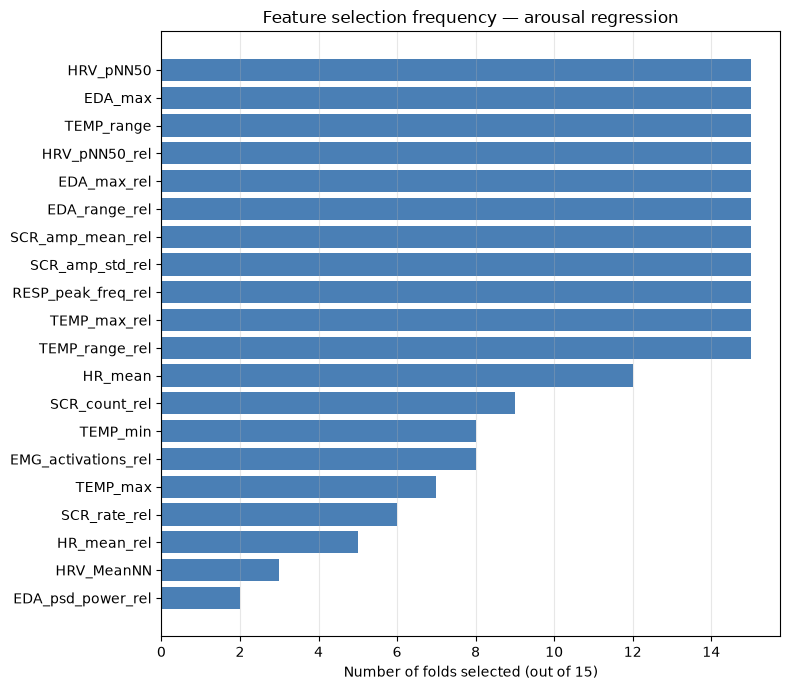

In [49]:
# Visualize the feature selection frequency
top = freq_reg_df.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top['feature'], top['folds_selected'], color='#4a7fb5')
ax.set_xlabel(f'Number of folds selected (out of {n_folds})')
ax.set_title('Feature selection frequency — arousal regression')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()